# Simulating DNA replication

Use `rsim` to explore individual S phases, ensemble variation, time courses, space–time fields and optional fork mechanisms. The model is synthetic, small and reproducible; increase the region or replicate count once the workflow is familiar.

Run all cells in order with DNAscape installed. No downloads are needed. Exports go to `examples/outputs/simulation/`.

1. Inputs, units and reproducibility
2. Individual profiles and ensemble summaries
3. Outputs over time
4. Space–time outputs
5. Periodicity, variable speed, stalling and firing factors
6. Export simulation results


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "simulation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import rsim, rsave, plotf

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\simulation


## 1. Inputs, units and reproducibility

`rsim` takes potential initiation rate **per bin per minute**, while fork speed stays in **kb/min**. Use `ir_per_kb * resolution_x` when starting with a density returned by `rmap`. Changing the spatial bin width changes the number of values required to cover a fixed genomic interval.

`resolution_t` controls sampling of temporal kinetic inputs; `time_grid` controls recorded time-course outputs. Set `seed` for reproducible ensembles and `max_rep_time` high enough for the region to finish.


In [2]:
DX_KB = 2.0
DT_MIN = 5.0
N_BINS = 160
REPLICATES = 64
SEED = 23
positions_kb = np.arange(N_BINS) * DX_KB
ir_per_kb = 0.002 * (1.0 + 0.6 * np.sin(positions_kb / 65.0) ** 2)
ir_per_bin = ir_per_kb * DX_KB
fork_speed = 1.4
output_times = np.arange(0.0, 401.0, DT_MIN)
TIME_VIEW = (0.0, 80.0)  # Display early dynamics; keep the full recorded grid.
source = {"initiation_rate": ir_per_bin, "fork_speed": fork_speed}
settings = {
    "resolution_x": DX_KB,
    "resolution_t": DT_MIN,
    "time_grid": output_times,
    "max_rep_time": 800.0,
    "verbose": False,
}
print(f"{N_BINS} bins cover {N_BINS * DX_KB:g} kb")


160 bins cover 320 kb


### Run one S phase and an ensemble

A retained ensemble already contains individual replication-time profiles; there is no need to rerun the model to plot example cells. `time_statsQ=True` adds origin firing over time, fork counts and completed replicon lengths.


In [3]:
single = rsim(source=source, assumptions={**settings, "sim_number": 1, "seed": SEED})
simulation = rsim(
    source=source,
    assumptions={
        **settings,
        "sim_number": REPLICATES,
        "seed": SEED,
        "time_statsQ": True,
        "time_stats_xtQ": True,
    },
)
individual = np.asarray(simulation["rep_times_per_sim"], dtype=float)
assert individual.shape == (REPLICATES, N_BINS)
assert np.isfinite(individual).all(), "Some bins are unfinished; increase max_rep_time."
pd.DataFrame(
    [
        {"Output": key, "Shape": np.asarray(value).shape}
        for key, value in simulation.items()
        if value is not None
        and key
        in {
            "replication_timing",
            "rep_times_per_sim",
            "origin_efficiency",
            "origin_firing",
            "replicon_lengths",
            "replicated_fraction_xt",
            "fork_density_xt",
        }
    ]
)


,Output,Shape
0,replication_timing,"(160,)"
1,rep_times_per_sim,"(64, 160)"
2,replicon_lengths,"(815,)"
3,origin_efficiency,"(160,)"
4,replicated_fraction_xt,"(160, 81)"
5,fork_density_xt,"(160, 81)"
6,origin_firing,"(81,)"


## 2. Individual profiles and ensemble summaries

The ensemble mean and standard deviation describe population timing, while individual profiles retain cell-to-cell variability. The shaded band below shows **±1 standard deviation**, not a confidence interval for the mean.


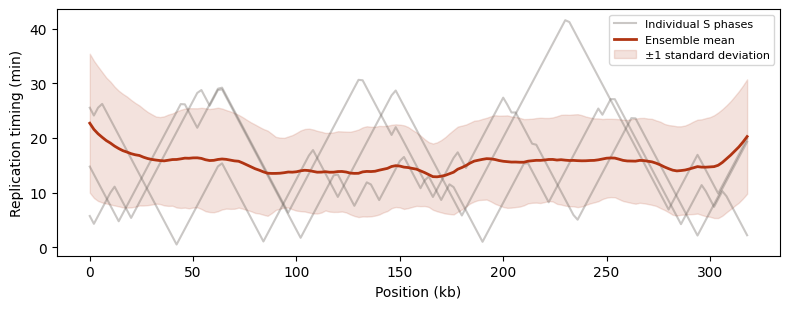

In [4]:
mean_timing = np.asarray(simulation["replication_timing"])
std_timing = individual.std(axis=0)
fig, ax = plt.subplots()
for index, profile in enumerate(individual[:3]):
    ax.plot(
        positions_kb,
        profile,
        color="#68615b",
        alpha=0.35,
        label="Individual S phases" if index == 0 else None,
    )
ax.plot(positions_kb, mean_timing, color="#b03412", label="Ensemble mean", linewidth=2)
ax.fill_between(
    positions_kb,
    mean_timing - std_timing,
    mean_timing + std_timing,
    color="#b03412",
    alpha=0.14,
    label="±1 standard deviation",
)
ax.set(xlabel="Position (kb)", ylabel="Replication timing (min)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Origin efficiency and directionality

Origin efficiency is the fraction of replicates in which a bin fired before passive replication. It differs from the supplied potential initiation rate. Directionality describes the mean direction of replication and lies between −1 and +1.


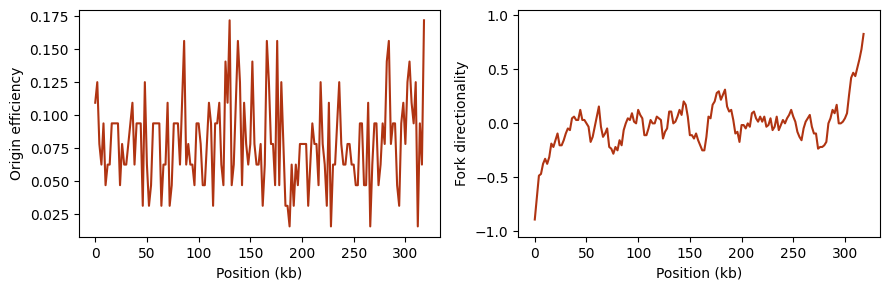

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(positions_kb, simulation["origin_efficiency"])
axes[0].set(xlabel="Position (kb)", ylabel="Origin efficiency")
axes[1].plot(positions_kb, simulation["fork_directionality"])
axes[1].set(xlabel="Position (kb)", ylabel="Fork directionality", ylim=(-1.05, 1.05))
fig.tight_layout()
plt.show()


### Per-replicate and single-molecule summaries

Completion time and fired-origin count have one value per replicate. Inter-origin distances pool separations between neighbouring fired origins. Replicon lengths instead measure completed DNA domains assigned to each fired origin; incomplete domains are excluded.


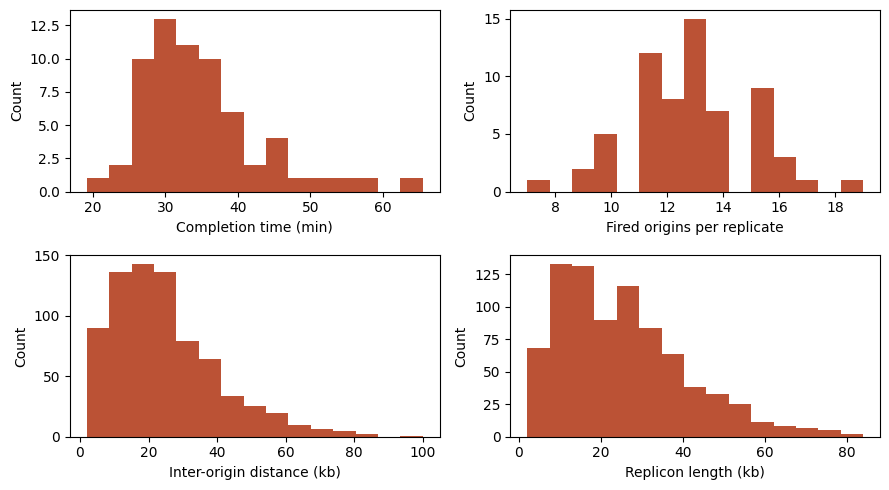

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for ax, key, label in zip(
    axes.flat,
    ["completion_time", "num_origins", "inter_origin_distance", "replicon_lengths"],
    [
        "Completion time (min)",
        "Fired origins per replicate",
        "Inter-origin distance (kb)",
        "Replicon length (kb)",
    ],
):
    values = np.asarray(simulation[key])
    ax.hist(values[np.isfinite(values)], bins=15, color="#b03412", alpha=0.85)
    ax.set(xlabel=label, ylabel="Count")
fig.tight_layout()
plt.show()


## 3. Outputs over time

All time courses use the returned `time_grid`. `origin_firing` counts actual initiations per recorded time interval, averaged over replicates. It is not the input hazard and should not be labelled initiation rate without dividing by interval width and choosing a spatial normalisation.

The figures focus on the first 80 minutes; exported arrays retain the full 0-400 minute recording.


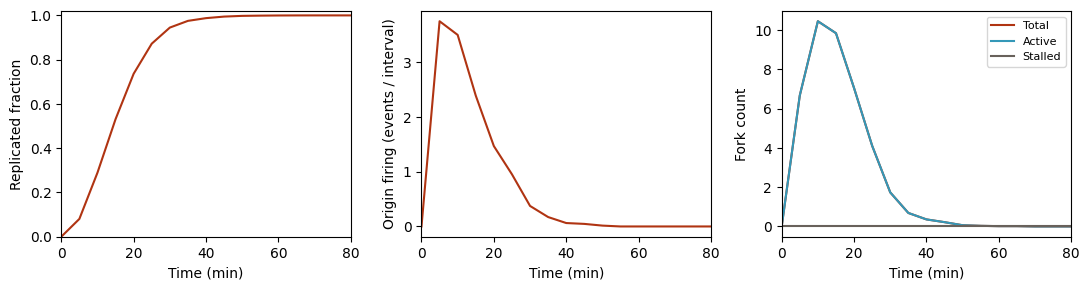

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(output_times, simulation["replicated_fraction"])
axes[0].set(xlabel="Time (min)", ylabel="Replicated fraction", ylim=(0, 1.02))
axes[1].plot(output_times, simulation["origin_firing"])
axes[1].set(xlabel="Time (min)", ylabel="Origin firing (events / interval)")
for key, label in [
    ("total_forks", "Total"),
    ("active_forks", "Active"),
    ("stalled_forks", "Stalled"),
]:
    axes[2].plot(output_times, simulation[key], label=label)
axes[2].set(xlabel="Time (min)", ylabel="Fork count")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.set_xlim(*TIME_VIEW)
fig.tight_layout()
plt.show()
np.testing.assert_allclose(
    np.sum(simulation["origin_firing"]), np.mean(simulation["num_origins"])
)


## 4. Space–time outputs

`time_stats_xtQ=True` adds position-by-time matrices. Event fields contain mean event **counts in recorded bins**; fork-density outputs use the simulator's spatial bin convention. These differ in normalisation from the continuous event-rate densities returned by `rmap`.

For large ensembles, limit spatial and time resolution before requesting these matrices. The present example has only 160 × 81 values per field.


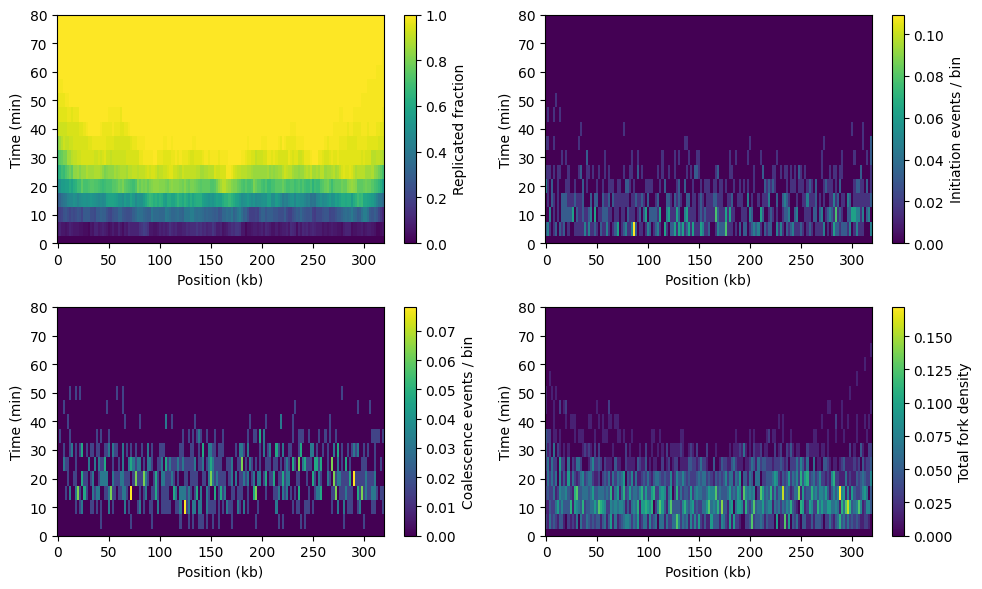

In [8]:
np.testing.assert_allclose(
    simulation["fork_density_xt"],
    simulation["right_fork_density_xt"] + simulation["left_fork_density_xt"],
)
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, key, label in zip(
    axes.flat,
    [
        "replicated_fraction_xt",
        "initiation_events_xt",
        "coalescence_events_xt",
        "fork_density_xt",
    ],
    [
        "Replicated fraction",
        "Initiation events / bin",
        "Coalescence events / bin",
        "Total fork density",
    ],
):
    image = ax.pcolormesh(
        positions_kb, output_times, np.asarray(simulation[key]).T, shading="auto"
    )
    ax.set(xlabel="Position (kb)", ylabel="Time (min)", ylim=TIME_VIEW)
    fig.colorbar(image, ax=ax, label=label)
fig.tight_layout()
plt.show()


## 5. Periodicity, variable speed, stalling and firing factors

Kinetic profiles can be constant, spatial, temporal or space–time. The following short comparison changes fork speed while keeping origin firing fixed. `fork_speed_std` models stochastic movement; a temporal speed input is a one-row matrix with spacing `resolution_t`.


In [9]:
mechanism_sources = {
    "Constant speed": source,
    "Spatial speed": {
        "initiation_rate": ir_per_bin,
        "fork_speed": 1.0 + 0.4 * np.cos(positions_kb / 70.0) ** 2,
    },
    "Temporal speed": {
        "initiation_rate": ir_per_bin,
        "fork_speed": (1.0 + output_times / 200.0)[None, :],
    },
    "Space–time speed": {
        "initiation_rate": ir_per_bin,
        "fork_speed": (1.0 + 0.3 * np.sin(positions_kb / 80.0))[:, None]
        * (1.0 + output_times[None, :] / 300.0),
    },
}
mechanisms = {
    name: rsim(
        source=inputs,
        assumptions={
            **settings,
            "sim_number": 16,
            "seed": SEED + 1,
            "time_statsQ": True,
        },
    )
    for name, inputs in mechanism_sources.items()
}
mechanisms["Stochastic speed"] = rsim(
    source=source,
    assumptions={
        **settings,
        "sim_number": 16,
        "seed": SEED + 1,
        "fork_speed_std": 1.0,
        "time_statsQ": True,
    },
)
# Temporal initiation also uses a one-row profile; supply the domain size explicitly.
for name, initiation in {
    "Temporal initiation": (0.002 * DX_KB * (1 + output_times / 60.0))[None, :],
    "Space-time initiation": ir_per_bin[:, None] * (1 + output_times[None, :] / 60.0),
}.items():
    mechanisms[name] = rsim(
        source={"initiation_rate": initiation, "fork_speed": fork_speed},
        assumptions={
            **settings,
            "n_bins": N_BINS,
            "sim_number": 16,
            "seed": SEED + 1,
            "time_statsQ": True,
        },
    )
pd.DataFrame(
    [
        {
            "Model": name,
            "Mean completion (min)": np.mean(result["completion_time"]),
            "Mean fired origins": np.mean(result["num_origins"]),
        }
        for name, result in mechanisms.items()
    ]
).round(2)


,Model,Mean completion (min),Mean fired origins
0,Constant speed,35.57,12.44
1,Spatial speed,38.98,13.31
2,Temporal speed,40.04,14.38
3,Space–time speed,39.23,14.00
4,Stochastic speed,41.95,15.25
5,Temporal initiation,32.97,12.88
6,Space-time initiation,30.32,13.81


### Shared or direction-independent stall positions

`stall_shared_directions=True` makes the same genomic stall positions affect forks arriving from either direction. It does not pause sister forks together. `False` gives direction-independent stall landscapes. `stall_rate_per_kb` specifies spatial stall density; `tau` is mean recovery time in minutes.


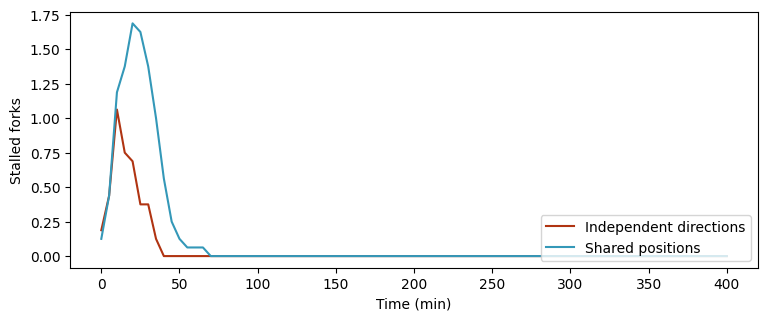

In [10]:
stall_runs = {}
for shared in (False, True):
    stall_runs[shared] = rsim(
        source=source,
        assumptions={
            **settings,
            "sim_number": 16,
            "seed": SEED + 2,
            "time_statsQ": True,
            "stall_rate_per_kb": 0.02,
            "tau": 8.0,
            "stall_shared_directions": shared,
        },
    )
plotf(
    stall_runs[False]["stalled_forks"],
    stall_runs[True]["stalled_forks"],
    x_array=output_times,
    labels=["Independent directions", "Shared positions"],
    xtitle="Time (min)",
    ytitle="Stalled forks",
    figsize=(8, 3.2),
)


### Limiting firing factors

A finite pool can restrict concurrent origin firing. `ffiring_forkQ=True` associates the pool with fork progression, while `ffiring_recycle` controls replenishment. Compare the available pool with actual origin firing over time.


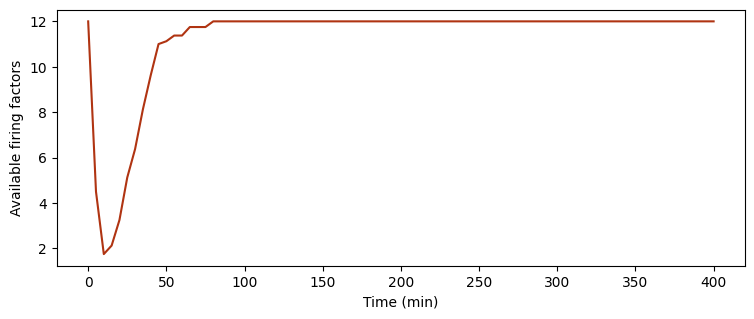

In [11]:
factor_run = rsim(
    source=source,
    assumptions={
        **settings,
        "sim_number": 16,
        "seed": SEED + 3,
        "time_statsQ": True,
        "ffiring_nr": 12,
        "ffiring_recycle": 0.05,
        "ffiring_forkQ": True,
    },
)
plotf(
    factor_run["firing_factors"],
    x_array=output_times,
    xtitle="Time (min)",
    ytitle="Available firing factors",
    figsize=(8, 3.2),
)


### A periodic domain

Periodic geometry wraps moving forks across the region boundary. Choose profiles that join smoothly if the underlying kinetic landscape is intended to be periodic. A circular drawing is a separate display choice; it does not enable periodic kinetics.


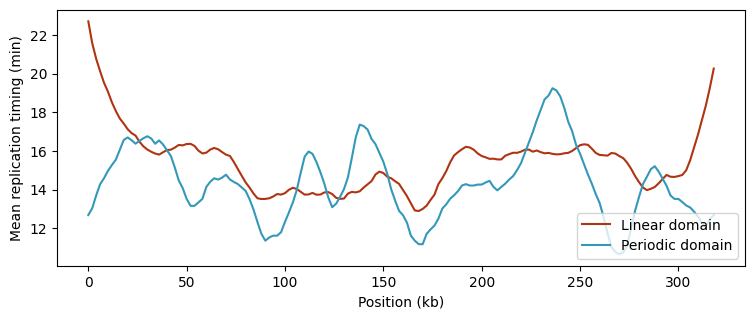

In [12]:
periodic_run = rsim(
    source=source,
    assumptions={
        **settings,
        "sim_number": 16,
        "seed": SEED + 4,
        "perQ": True,
        "time_statsQ": True,
    },
)
plotf(
    simulation["replication_timing"],
    periodic_run["replication_timing"],
    x_array=positions_kb,
    labels=["Linear domain", "Periodic domain"],
    xtitle="Position (kb)",
    ytitle="Mean replication timing (min)",
    figsize=(8, 3.2),
)


## 6. Export simulation results

NPZ is convenient for full-resolution matrices; TSV is readable for compact summaries. Retain the seed, axes, rate convention and fork-speed units. For larger workloads, `retain_rep_times_limit`, `retain_inter_origin_distances_limit` and `retain_replicon_lengths_limit` bound retained samples without reducing the ensemble size.


In [13]:
rsave(
    pd.DataFrame(
        {
            "completion_time_min": simulation["completion_time"],
            "fired_origins": simulation["num_origins"],
        }
    ),
    OUTPUT_DIR / "replicate_summaries.tsv",
)
np.savez_compressed(
    OUTPUT_DIR / "simulation_xt.npz",
    positions_kb=positions_kb,
    time_min=output_times,
    resolution_kb=DX_KB,
    seed=SEED,
    replicates=REPLICATES,
    initiation_rate_per_bin_min=ir_per_bin,
    fork_speed_kb_min=fork_speed,
    timing_mean_min=mean_timing,
    timing_std_min=std_timing,
    origin_firing_events=simulation["origin_firing"],
    replicon_lengths_kb=simulation["replicon_lengths"],
    replicated_fraction_xt=simulation["replicated_fraction_xt"],
    fork_density_xt=simulation["fork_density_xt"],
)
print("Saved replicate_summaries.tsv and simulation_xt.npz")


Saved replicate_summaries.tsv and simulation_xt.npz


Continue with [worked perturbation studies](4-neat_examples.ipynb) or [plotting and interactive exports](5-plotting.ipynb). `rsim.input()` and `rsim.output()` list current options and output definitions; the [simulation documentation](https://dnascape.readthedocs.io/en/latest/simulationengine.html) explains the model in more detail.
